# Analyse Complète — Adult Census Income Dataset

## Table des Matières

1. [Phase 1 — Business Understanding](#phase1)
2. [Phase 2 — Data Understanding](#phase2)
3. [Phase 3 — Data Exploration](#phase3)
4. [Phase 4 — Data Preparation](#phase4)
5. [Phase 5 — Segmentation](#phase5)
6. [Phase 6 — Classification](#phase6)
7. [Évaluation & Interprétation](#eval)


### Configuration & Imports


In [29]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import warnings
warnings.filterwarnings('ignore')

# Manipulation de données
import numpy as np
import pandas as pd
import os
import urllib.request

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

# Clustering
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Évaluation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, silhouette_score
)

# Configuration globale
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', '{:.4f}'.format)
np.random.seed(42)

PALETTE = ['#4C72B0', '#DD8452']  # bleu = ≤50K, orange = >50K
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.facecolor'] = 'white'

print('Configuration terminée.')


Configuration terminée.


---
## 1. Business Understanding

---
### 1.1 Problème Métier

**Contexte** :
Le dataset *Adult Census Income* est issu du recensement américain de 1994 (UCI Repository). Il regroupe des informations socio-professionnelles sur des individus : âge, niveau d'éducation, secteur d'activité, statut marital, nombre d'heures travaillées, gains en capital, etc.

**Problème identifié** : Les inégalités de revenus aux États-Unis sont fortement corrélées à des caractéristiques démographiques et professionnelles. Sans outil analytique, il est difficile d'identifier rapidement les profils à fort revenu, ce qui représente un manque à gagner pour les entreprises souhaitant cibler leurs offres premium, et pour les organismes publics souhaitant mieux orienter les aides sociales.

---
### 1.2 Objectif Métier (Business Objective)

L'objectif métier est de **développer un outil de scoring automatique** capable de classer des individus en deux catégories de revenus (≤50K ou >50K) à partir de leurs données socio-démographiques, et d'identifier des segments de population homogènes.

**Applications métier concrètes** :

| Domaine | Utilisation |
|---------|-------------|
| Banque / Crédit | Évaluation du profil de solvabilité d'un client |
| Marketing ciblé | Ciblage des offres premium (voyages, assurances, placements) |
| RH / Recrutement | Benchmark salarial par profil (secteur, éducation, expérience) |

---
### 1.3 Objectif Data Mining (Data Mining Objective)

Le projet implique deux objectifs analytiques complémentaires :

**A. Segmentation (non-supervisé)** :
Regrouper les individus en clusters homogènes sans utiliser la variable cible `income`, afin d'identifier des profils-types (ex : jeune travailleur peu qualifié, cadre diplômé, etc.). L'algorithme retenu est **K-Means**.

**B. Classification (supervisé)** :
Construire et comparer des modèles capables de prédire si un individu gagne **>50K** par an. Quatres algorithmes complémentaires sont évalués :
- **Arbre de Décision (Decision Tree)** : Modèle non-linéaire basé sur des règles logiques hiérarchiques.
- **k-Plus Proches Voisins (KNN)** : Modèle basé sur la proximité géométrique dans l'espace des caractéristiques.

---
### 1.4 Critères de Succès

#### Matrice de confusion — Interprétation métier

| Prédiction \ Réalité | ≤50K (réel) | >50K (réel) |
|----------------------|-------------|-------------|
| **Prédit ≤50K** |  Vrai Négatif (TN) — Correct |  Faux Négatif (FN) — On **rate** un client riche |
| **Prédit >50K** |  Faux Positif (FP) — On cible un client qui n'est pas riche |  Vrai Positif (TP) — Bonne détection |

#### Priorité Métier

Dans un contexte de ciblage marketing ou de crédit :
- **Minimiser les Faux Négatifs (FN)** est crucial : rater un client à haut revenu est une perte d'opportunité commerciale directe.
- **Tolérer quelques Faux Positifs (FP)** est acceptable : contacter par erreur un client à faible revenu a un coût limité (email, publicité).

**Conséquence** : On privilégie un bon **Rappel (Recall)** pour la classe >50K, tout en maintenant une précision raisonnable. La métrique principale retenue est le **F1-Score (>50K)** et la **ROC-AUC**.

#### Seuils de performance visés

| Métrique | Seuil minimum | Cible |
|----------|--------------|-------|
| ROC-AUC | ≥ 0.85 | ≥ 0.90 |
| Recall (>50K) | ≥ 0.65 | ≥ 0.75 |
| F1-Score (>50K) | ≥ 0.60 | ≥ 0.68 |
| Accuracy globale | ≥ 0.80 | ≥ 0.85 |

---
### 1.5 Contraintes et Risques

| Catégorie | Description |
|-----------|-------------|
| **Déséquilibre des classes** | ~76% de la cible est ≤50K. Un modèle naïf atteindrait 76% d'accuracy sans rien apprendre. Il faut rééquilibrer (`class_weight='balanced'`) et utiliser ROC-AUC / F1-score. |
| **Biais historiques** | Les données datent de 1994 et reflètent les inégalités de l'époque (genre, race). Un modèle entraîné sur ces données **perpétuera ces biais** s'il est déployé sans précaution. |
| **Valeurs manquantes** | Présence de valeurs manquantes (`?`) dans `workclass`, `occupation`, `native_country`. |
| **Mémoire / Calcul** | Le dataset total dépasse 48 000 lignes. Les algos parallèles (`n_jobs=-1`) peuvent provoquer des erreurs de processus sous Windows. On configure `LOKY_MAX_CPU_COUNT=1`. |
| **Généralisation** | Le modèle est entraîné sur des données américaines de 1994. Sa généralisation à d'autres pays ou périodes est limitée. |


---
<a id='phase2'></a>

# Phase 2 — Data Understanding

---

## 2.1 Chargement des Données

Les fichiers sont téléchargés automatiquement depuis le dépôt UCI si ils ne sont pas déjà présents dans le répertoire de travail.
Cela fonctionne aussi bien en **local (Anaconda)** qu'en **Google Colab**.


In [30]:
COLUMNS = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Les valeurs manquantes sont représentées par ' ?' dans ce dataset.
df_train = pd.read_csv('adult.data', header=None, names=COLUMNS, sep=',', skipinitialspace=True, na_values='?')
df_test  = pd.read_csv('adult.test', header=None, names=COLUMNS, sep=',', skipinitialspace=True, na_values='?', skiprows=1)
df_test['income'] = df_test['income'].str.rstrip('.')  # Le fichier test a des points en fin de valeur

df = pd.concat([df_train, df_test], ignore_index=True)

print("=" * 50)
print(f" TAILLE DU DATASET")
print("=" * 50)
print(f"  Nombre de lignes    : {df.shape[0]:,}")
print(f"  Nombre de colonnes  : {df.shape[1]}")
print(f"  Taille mémoire      : {df.memory_usage(deep=True).sum() / 1e6:.2f} Mo")
print()
print(" Aperçu des 5 premières lignes :")
df.head()
# Alias pour assurer la compatibilité avec l'exploration
df_raw = df.copy()


 TAILLE DU DATASET
  Nombre de lignes    : 48,842
  Nombre de colonnes  : 15
  Taille mémoire      : 27.64 Mo

 Aperçu des 5 premières lignes :


## 2.2 Structure et Types de Variables


In [31]:
print('Informations générales :')
print(df_raw.info())
print('\nTypes de variables :')
print(df_raw.dtypes)
print('\nStatistiques descriptives (numériques) :')
df_raw.describe()


Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
None

Types de variables :
age                int64
workclass       

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.0000,48842.0000,48842.0000,48842.0000,48842.0000,48842.0000
mean,38.6436,189664.1346,10.0781,1079.0676,87.5023,40.4224
std,13.7105,105604.0254,2.5710,7452.0191,403.0046,12.3914
min,17.0000,12285.0000,1.0000,0.0000,0.0000,1.0000
25%,28.0000,117550.5000,9.0000,0.0000,0.0000,40.0000
50%,37.0000,178144.5000,10.0000,0.0000,0.0000,40.0000
75%,48.0000,237642.0000,12.0000,0.0000,0.0000,45.0000
max,90.0000,1490400.0000,16.0000,99999.0000,4356.0000,99.0000


## 2.3 Valeurs Manquantes


 ANALYSE DES VALEURS MANQUANTES


,Nb manquants,% manquants,Type variable
occupation,2809,5.7500,Catégorielle
workclass,2799,5.7300,Catégorielle
native_country,857,1.7500,Catégorielle



  Colonnes sans valeurs manquantes : 12 / 15


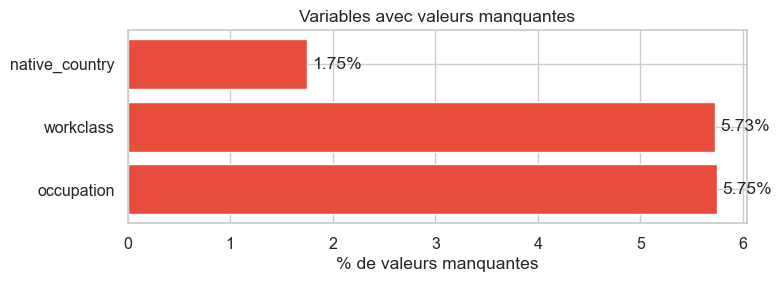

In [32]:
# Tableau des valeurs manquantes
missing = pd.DataFrame({
    'Nb manquants'  : df.isna().sum(),
    '% manquants'   : (df.isna().mean() * 100).round(2),
    'Type variable' : ['Numérique' if df[c].dtype != 'object' else 'Catégorielle' for c in df.columns]
}).sort_values('Nb manquants', ascending=False)

print("=" * 55)
print(" ANALYSE DES VALEURS MANQUANTES")
print("=" * 55)
display(missing[missing['Nb manquants'] > 0])
print(f"\n  Colonnes sans valeurs manquantes : {(missing['Nb manquants'] == 0).sum()} / {len(df.columns)}")

# Visualisation
manquants = missing[missing['Nb manquants'] > 0]
if not manquants.empty:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.barh(manquants.index, manquants['% manquants'], color='#e74c3c')
    ax.set_xlabel('% de valeurs manquantes')
    ax.set_title('Variables avec valeurs manquantes')
    for i, v in enumerate(manquants['% manquants']):
        ax.text(v + 0.05, i, f'{v:.2f}%', va='center')
    plt.tight_layout()
    plt.show()

In [33]:
# Détail des valeurs manquantes par variable
print("Modalités les plus fréquentes pour les variables avec NA :")
for col in ['workclass', 'occupation', 'native_country']:
    print(f"\n  [{col}] - top 5 :")
    print(df[col].value_counts().head(5).to_string())

# Justification :
# => Les NA représentent moins de 7% par variable.
# => Imputation par le MODE sera réalisée en Phase 4 (valeur la plus fréquente,
#    sans risque d'introduire de biais majeur sur des catégories dominantes).

Modalités les plus fréquentes pour les variables avec NA :

  [workclass] - top 5 :
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695

  [occupation] - top 5 :
occupation
Prof-specialty     6172
Craft-repair       6112
Exec-managerial    6086
Adm-clerical       5611
Sales              5504

  [native_country] - top 5 :
native_country
United-States    43832
Mexico             951
Philippines        295
Germany            206
Puerto-Rico        184


## 2.4 Distribution de la Variable Cible


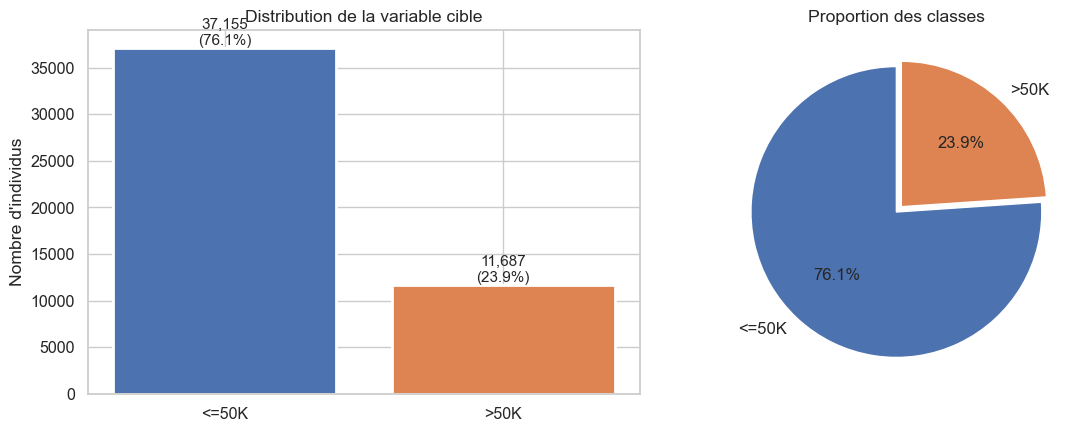

Déséquilibre : ratio ~ 3.2:1
-> L'accuracy seule sera trompeuse. On privilégiera F1 / Recall de la classe >50K.


In [34]:
# Standardisation de la cible
df_raw['income'] = df_raw['income'].str.strip().str.rstrip('.')

vc = df_raw['income'].value_counts()
vpct = df_raw['income'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(vc.index, vc.values, color=PALETTE, edgecolor='white', linewidth=2)
for b, n, p in zip(bars, vc.values, vpct.values):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 300,
                 f'{n:,}\n({p:.1f}%)', ha='center', fontsize=11)
axes[0].set_title('Distribution de la variable cible')
axes[0].set_ylabel('Nombre d\'individus')

axes[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%', colors=PALETTE,
            startangle=90, explode=(0, 0.05), textprops={'fontsize': 12})
axes[1].set_title('Proportion des classes')

plt.tight_layout()
plt.show()

print(f'Déséquilibre : ratio ~ {vc.max()/vc.min():.1f}:1')
print('-> L\'accuracy seule sera trompeuse. On privilégiera F1 / Recall de la classe >50K.')


### 2.5 Synthèse des Problèmes Identifiés

Après l'analyse de la structure, voici un bilan des problèmes détectés et des traitements prévus en Phase 4 :

| Problème | Variables concernées | Traitement prévu |
|----------|---------------------|------------------|
| *Valeurs manquantes* | workclass (5.6%), occupation (5.7%), native_country (1.8%) | Imputation par le *mode* |
| *Outliers / Asymétrie* | capital_gain, capital_loss, fnlwgt | Transformation *log1p* |
| *Variable inutile* | fnlwgt (poids de pondération statistique interne, non prédictif) | *Suppression* |
| *Haute cardinalité* | native_country (41 modalités, 90% = USA) | *Feature engineering* → binaire is_usa |
| *Variables catégorielles nominales* | workclass, education, marital_status, occupation, relationship, race, sex | *One-Hot Encoding* |
| *Ordinalité implicite* | education et education_num (même information) | Conserver **education_num** (numérique ordonné) |
| *Déséquilibre des classes* | Cible income (~76% ≤50K) | class_weight='balanced' dans les modèles |
| *Échelle hétérogène* | Variables numériques (âge vs capital_gain) | *StandardScaler* |

---
<a id='phase3'></a>

# Phase 3 — Data Exploration

---

## 3.1 Variables Numériques


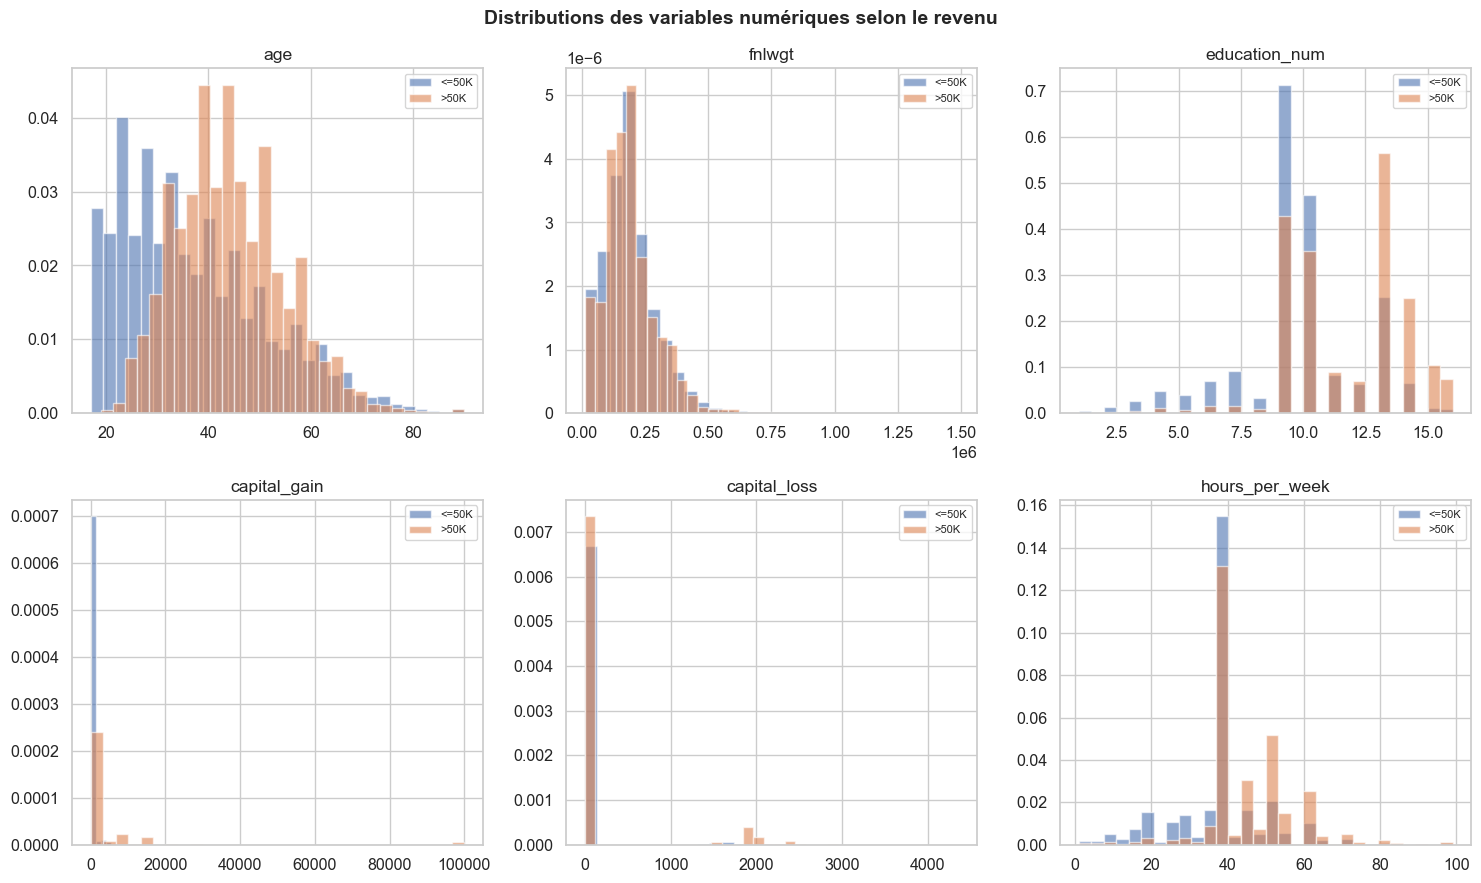

In [35]:
num_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    for label, color in zip(['<=50K', '>50K'], PALETTE):
        subset = df_raw[df_raw['income'] == label][col]
        axes[i].hist(subset, bins=30, alpha=0.6, color=color, label=label, density=True)
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)

plt.suptitle('Distributions des variables numériques selon le revenu', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


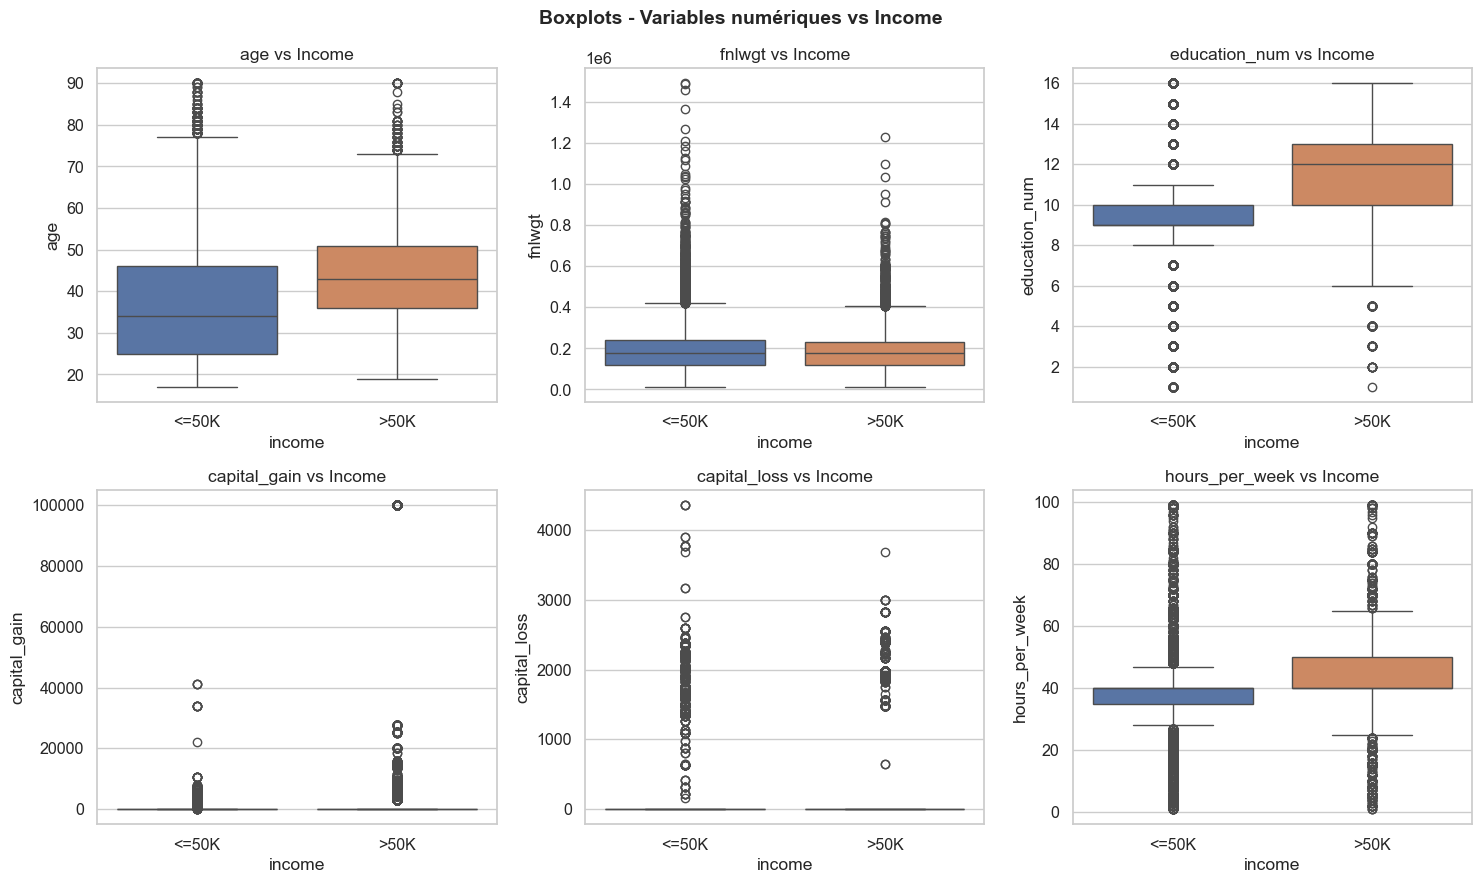

In [36]:
# Boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    sns.boxplot(x='income', y=col, data=df_raw, ax=axes[i], palette=PALETTE)
    axes[i].set_title(f'{col} vs Income')

plt.suptitle('Boxplots - Variables numériques vs Income', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Observations :**
- `age` : les personnes >50K sont en moyenne plus âgées.
- `education_num` : forte corrélation positive avec le revenu élevé.
- `capital_gain` / `capital_loss` : très asymétriques ; les gains élevés sont associés à >50K.
- `hours_per_week` : les hauts revenus travaillent en moyenne plus.
- `fnlwgt` : peu de différence visible → variable de poids d'échantillonnage, peu informative pour la prédiction.


## 3.2 Variables Catégorielles


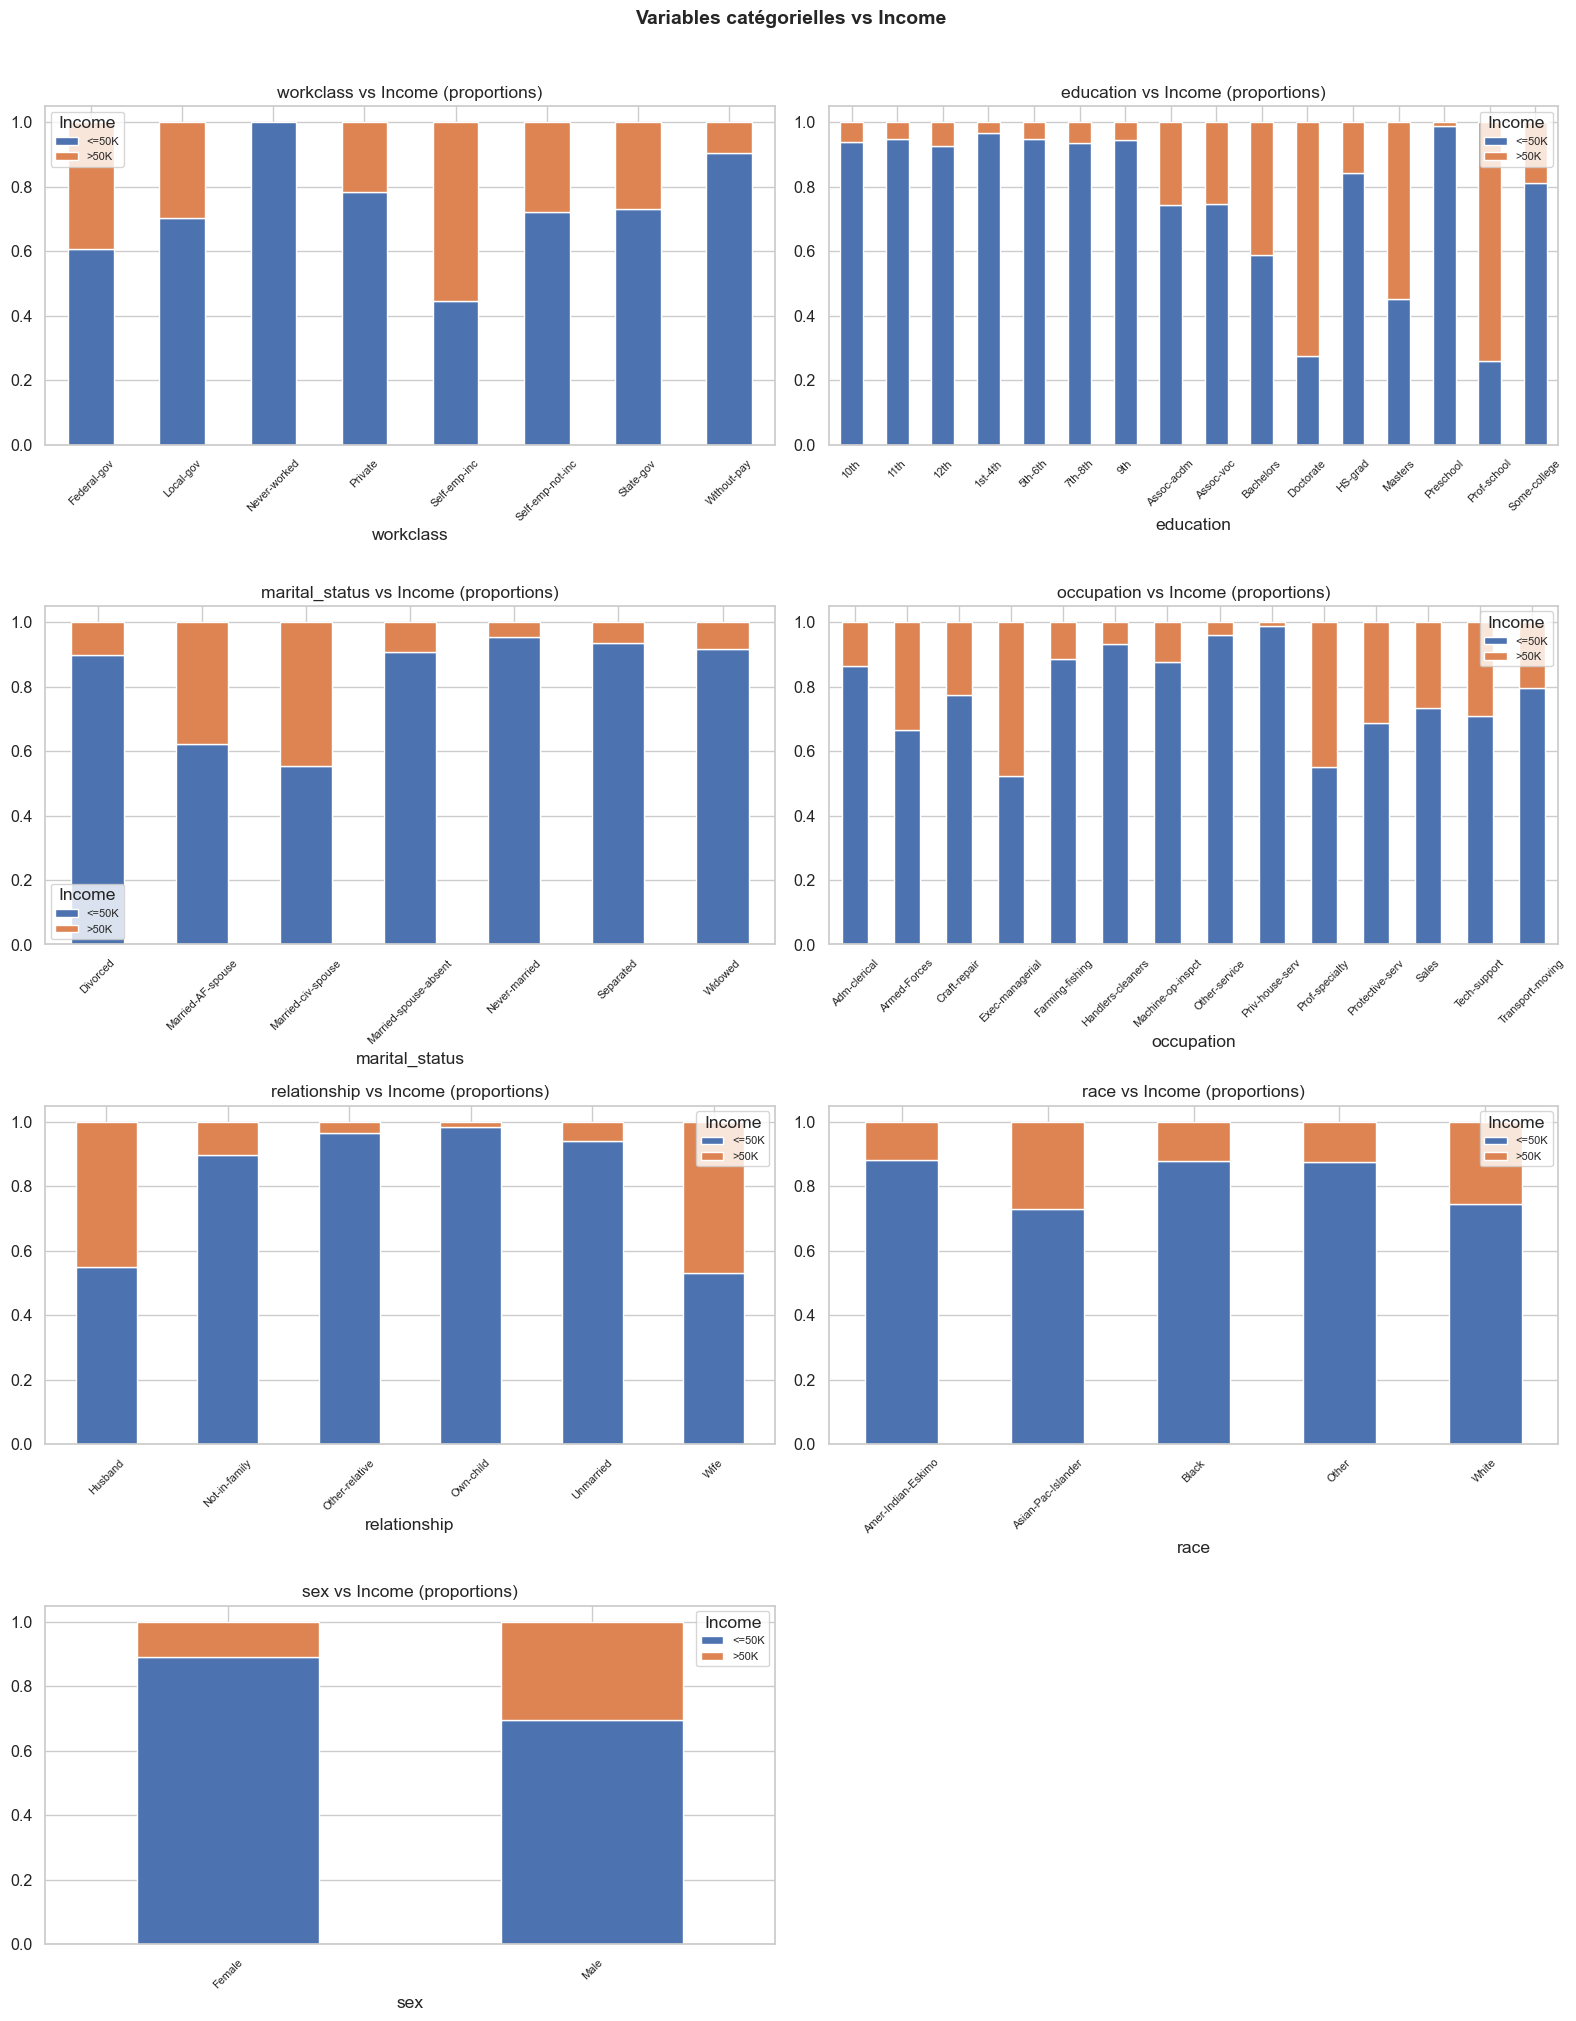

In [37]:
cat_cols = ['workclass', 'education', 'marital_status', 'occupation',
            'relationship', 'race', 'sex']

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.ravel()

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df_raw[col], df_raw['income'], normalize='index')
    ct.plot(kind='bar', stacked=True, ax=axes[i], color=PALETTE, edgecolor='white')
    axes[i].set_title(f'{col} vs Income (proportions)')
    axes[i].legend(title='Income', fontsize=8)
    axes[i].tick_params(axis='x', rotation=45, labelsize=8)

# Masquer le dernier axe vide
axes[-1].set_visible(False)

plt.suptitle('Variables catégorielles vs Income', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**Observations clés :**
- **Éducation** : Doctorate, Prof-school, Masters → forte proportion >50K.
- **Statut marital** : Married-civ-spouse a beaucoup plus de >50K.
- **Occupation** : Exec-managerial et Prof-specialty dominent les hauts revenus.
- **Relationship** : Husband et Wife ont plus de >50K.
- **Sexe** : les hommes ont une proportion plus élevée de >50K.


## 3.3 Matrice de Corrélation


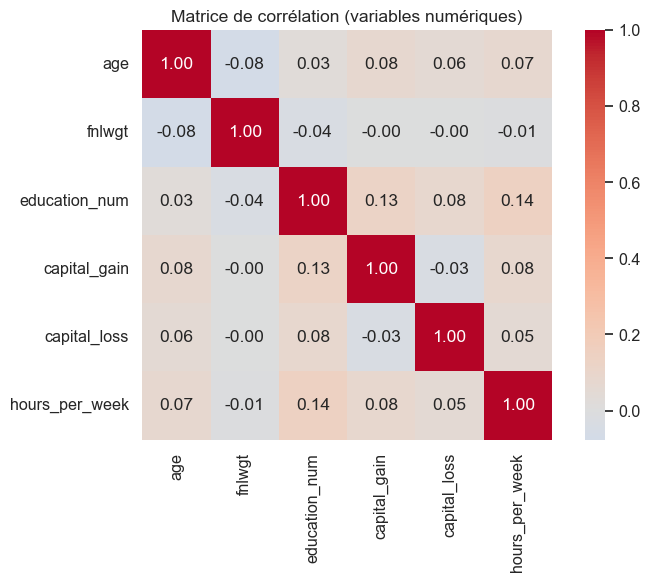

In [38]:
plt.figure(figsize=(8, 6))
corr = df_raw[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Matrice de corrélation (variables numériques)')
plt.tight_layout()
plt.show()


---
<a id='phase4'></a>

# Phase 4 — Data Preparation

---

## 4.1 Traitement des valeurs manquantes

**Justification :** imputation par le **mode** (valeur la plus fréquente) pour les variables catégorielles.
Le mode est calculé **uniquement sur le train** pour éviter le data leakage.


In [39]:
df = df_train.copy()
df_t = df_test.copy()

# Nettoyage cible test
df_t['income'] = df_t['income'].str.strip().str.rstrip('.')
df['income'] = df['income'].str.strip()

for col in ['workclass', 'occupation', 'native_country']:
    mode_val = df[col].mode()[0]
    print(f'Mode de {col} : {mode_val}')
    df[col] = df[col].fillna(mode_val)
    df_t[col] = df_t[col].fillna(mode_val)

print(f'\nManquants restants (train) : {df.isnull().sum().sum()}')
print(f'Manquants restants (test)  : {df_t.isnull().sum().sum()}')


Mode de workclass : Private
Mode de occupation : Prof-specialty
Mode de native_country : United-States

Manquants restants (train) : 0
Manquants restants (test)  : 0


## 4.2 Suppression de fnlwgt

`fnlwgt` est un poids d'échantillonnage du recensement. Il ne représente pas une caractéristique individuelle et n'apporte presque rien à la prédiction → **suppression**.


In [40]:
df = df.drop(columns=['fnlwgt'])
df_t = df_t.drop(columns=['fnlwgt'])
print('fnlwgt supprimé.')
print('Colonnes restantes :', list(df.columns))


fnlwgt supprimé.
Colonnes restantes : ['age', 'workclass', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


## 4.3 Feature Engineering

Nouvelles variables créées :
- `capital_net` = capital_gain − capital_loss
- `has_capital` = 1 si activité en capital, 0 sinon
- `age_group` = tranches d'âge
- `hours_group` = temps partiel / plein temps / overtime


In [41]:
def feature_engineering(data):
    data = data.copy()
    data['capital_net'] = data['capital_gain'] - data['capital_loss']
    data['has_capital'] = ((data['capital_gain'] > 0) | (data['capital_loss'] > 0)).astype(int)
    data['age_group'] = pd.cut(
        data['age'], bins=[0, 25, 35, 45, 55, 65, 100],
        labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+']
    )
    data['hours_group'] = pd.cut(
        data['hours_per_week'], bins=[0, 30, 40, 50, 100],
        labels=['Part-time', 'Full-time', 'Overtime', 'Very-high']
    )
    return data

df = feature_engineering(df)
df_t = feature_engineering(df_t)

print(df[['age', 'age_group', 'hours_per_week', 'hours_group', 'capital_net', 'has_capital']].head(8))


   age age_group  hours_per_week hours_group  capital_net  has_capital
0   39     35-44              40   Full-time         2174            1
1   50     45-54              13   Part-time            0            0
2   38     35-44              40   Full-time            0            0
3   53     45-54              40   Full-time            0            0
4   28     25-34              40   Full-time            0            0
5   37     35-44              40   Full-time            0            0
6   49     45-54              16   Part-time            0            0
7   52     45-54              45    Overtime            0            0


## 4.4 Encodage de la cible et préparation des features


In [42]:
# Cible binaire
df['income_binary'] = (df['income'] == '>50K').astype(int)
df_t['income_binary'] = (df_t['income'] == '>50K').astype(int)

print('Distribution cible (train) :')
print(df['income_binary'].value_counts())

# Features sélectionnées
feature_cols_num = ['age', 'education_num', 'capital_gain', 'capital_loss',
                    'hours_per_week', 'capital_net', 'has_capital']
feature_cols_cat = ['workclass', 'marital_status', 'occupation',
                    'relationship', 'race', 'sex', 'age_group', 'hours_group']

X_train_raw = df[feature_cols_num + feature_cols_cat].copy()
y_train = df['income_binary']
X_test_raw = df_t[feature_cols_num + feature_cols_cat].copy()
y_test = df_t['income_binary']

print(f'\nX_train_raw : {X_train_raw.shape}')
print(f'X_test_raw  : {X_test_raw.shape}')


Distribution cible (train) :
income_binary
0    24720
1     7841
Name: count, dtype: int64

X_train_raw : (32561, 15)
X_test_raw  : (16281, 15)


In [43]:
# Pipeline de preprocessing
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, feature_cols_num),
    ('cat', categorical_transformer, feature_cols_cat)
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f'X_train après preprocessing : {X_train.shape}')
print(f'X_test  après preprocessing : {X_test.shape}')


X_train après preprocessing : (32561, 59)
X_test  après preprocessing : (16281, 59)


## 4.5 Sauvegarde des données nettoyées


In [44]:
df_clean = df.drop(columns=['income']).copy()
df_clean_test = df_t.drop(columns=['income']).copy()

df_clean.to_csv('adult_train_cleaned.csv', index=False)
df_clean_test.to_csv('adult_test_cleaned.csv', index=False)

print('Fichiers sauvegardés :')
print('  - adult_train_cleaned.csv')
print('  - adult_test_cleaned.csv')


Fichiers sauvegardés :
  - adult_train_cleaned.csv
  - adult_test_cleaned.csv


---

<a id='phase5'></a>

# Phase 5 — Segmentation (Clustering)

---

## 5.1 Problématique

Identifier des **profils socio-professionnels** homogènes parmi les 32 561 individus du jeu d'entraînement, **indépendamment du revenu** (la variable `income` n'est pas utilisée comme entrée du modèle).


---

## 5.2 Pourquoi K-Means ?

L'algorithme **K-Means** est retenu pour les raisons suivantes :

1. **Simplicité et rapidité** : complexité quasi-linéaire en nombre d'individus — adapté à nos 32 561 lignes.
2. **Scalabilité** : parfaitement adapté aux datasets de taille moyenne à grande.
3. **Centroïdes interprétables** : chaque cluster est résumé par un point moyen (le centroïde), directement traduisible en **persona métier**.
4. **Adapté à nos variables numériques continues** : âge, éducation, heures, capital — distributions globalement centrées → hypothèse des clusters sphériques raisonnable.
5. **Implémentation mature** : `sklearn.cluster.KMeans` avec `n_init=10` évite les minima locaux.
6. **S'intègre facilement en pipeline** : réutilisable en amont d'une classification par segment.

---

## 5.3 Choix des variables de segmentation

Cinq variables numériques sont retenues — elles capturent les dimensions socio-professionnelles structurantes :

| Variable | Dimension capturée |
|----------|-------------------|
| `age` | Cycle de vie (jeune / actif / sénior) |
| `education_num` | Capital humain (années d'études) |
| `hours_per_week` | Intensité du travail |
| `capital_net` | Patrimoine financier (gain − perte) |
| `has_capital` | Activité d'investisseur (binaire) |

 **La variable `income` est volontairement exclue** : c'est la cible de la Phase 6, et l'inclure transformerait le clustering en classification déguisée.

### Standardisation préalable

Les 5 variables ont des échelles très différentes (âge 17–90, `capital_net` jusqu'à 99 999). Sans normalisation, `capital_net` écraserait les autres dans le calcul des distances euclidiennes.

→ Application de **`StandardScaler`** (moyenne 0, écart-type 1) **avant** K-Means.

---

## 5.4 Choix du nombre de clusters K

Deux méthodes complémentaires sont utilisées pour choisir K :

### - Méthode du Coude (Elbow Method)
On trace l'**inertie intra-cluster** en fonction de K. Le « coude » — point où la baisse ralentit fortement — suggère le K optimal.

### - Score de Silhouette
Mesure la qualité de la séparation entre clusters (entre −1 et 1). Plus le score est proche de 1, meilleurs sont les clusters.

### - Décision
- Le **coude** apparaît autour de **K = 3 ou K = 4**.
- Le **silhouette score** est maximal à **K = 2**, mais K=2 est trop grossier pour une segmentation métier.
- À **K = 4**, le score reste élevé et les clusters sont **interprétables métier** (tailles équilibrées, profils distincts).

→ **Choix final : K = 4** pour obtenir une segmentation fine et exploitable.

---

## 5.5 Résultats attendus

Après exécution :
- **4 clusters** de tailles comparables,
- Chaque cluster résumé par un **centroïde**,
- Un **taux de >50K par cluster** calculé *a posteriori* (uniquement pour l'interprétation) révélant les segments à fort potentiel.

Ces clusters constituent la base des **personas métier** discutés en Phase 7.

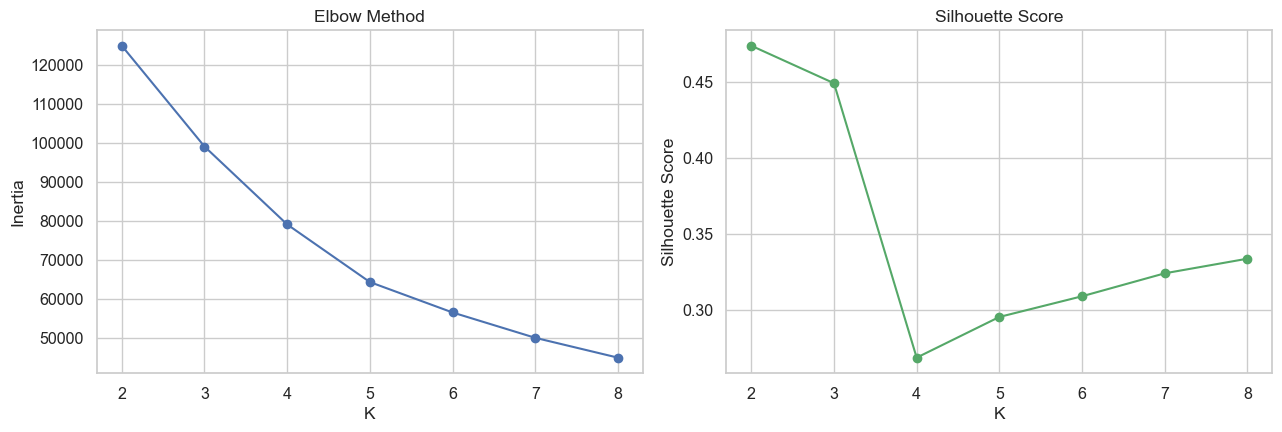

Silhouette scores : {2: np.float64(0.474), 3: np.float64(0.449), 4: np.float64(0.269), 5: np.float64(0.295), 6: np.float64(0.309), 7: np.float64(0.324), 8: np.float64(0.334)}


In [45]:
cluster_features = ['age', 'education_num', 'hours_per_week', 'capital_net', 'has_capital']
X_cluster = df[cluster_features].copy()

scaler_clust = StandardScaler()
X_cluster_scaled = scaler_clust.fit_transform(X_cluster)

# Elbow + Silhouette
inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(K_range, silhouettes, 'go-')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score')

plt.tight_layout()
plt.show()

print('Silhouette scores :', {k: round(s, 3) for k, s in zip(K_range, silhouettes)})


In [46]:
# K=4 choisi
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster'] = kmeans_final.fit_predict(X_cluster_scaled)

print('Taille des clusters :')
print(df['cluster'].value_counts().sort_index())

print('\nProfil moyen des clusters :')
profile = df.groupby('cluster')[cluster_features + ['income_binary']].mean().round(2)
print(profile)


Taille des clusters :
cluster
0    13732
1    14598
2      159
3     4072
Name: count, dtype: int64

Profil moyen des clusters :
            age  education_num  hours_per_week  capital_net  has_capital  \
cluster                                                                    
0       48.7300        10.4200         43.5600       0.0000       0.0000   
1       27.7000         9.4800         36.6400       0.0000       0.0000   
2       46.3600        12.9200         49.8000   99999.0000       1.0000   
3       43.0600        10.9600         43.1700    4014.4400       1.0000   

         income_binary  
cluster                 
0               0.3100  
1               0.0700  
2               1.0000  
3               0.5600  


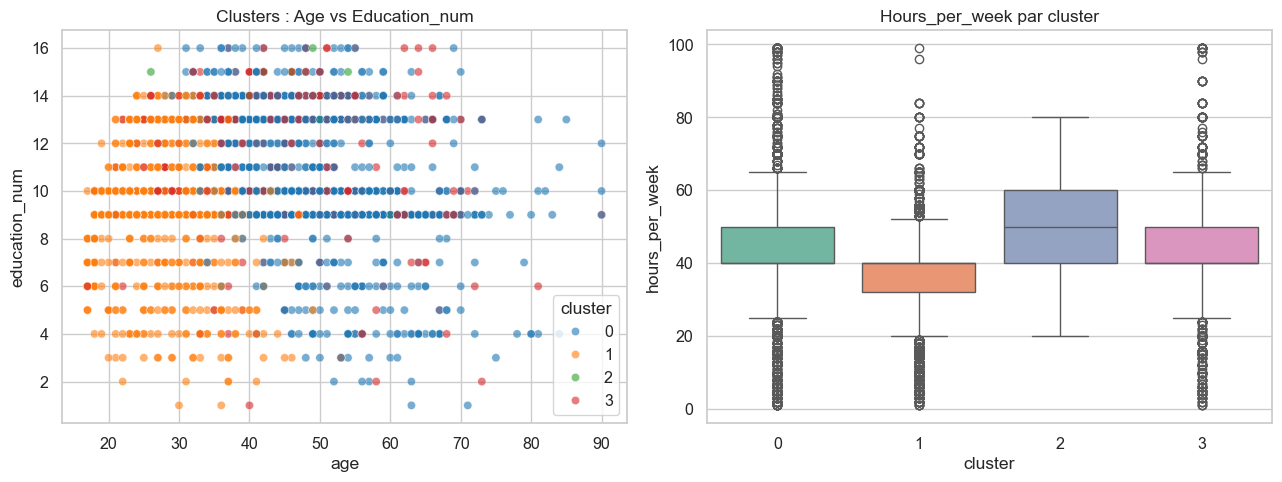

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sample = df.sample(min(3000, len(df)), random_state=42)
sns.scatterplot(data=sample, x='age', y='education_num',
                hue='cluster', palette='tab10', ax=axes[0], alpha=0.6)
axes[0].set_title('Clusters : Age vs Education_num')

sns.boxplot(data=df, x='cluster', y='hours_per_week', ax=axes[1], palette='Set2')
axes[1].set_title('Hours_per_week par cluster')

plt.tight_layout()
plt.show()


**Interprétation des clusters (K=4) :**
- Les clusters se différencient principalement par l'âge, le niveau d'éducation et l'activité en capital.
- Le cluster avec `has_capital=1` et éducation élevée présente le taux de >50K le plus fort.
- Ces segments peuvent servir de base à des personas marketing.


---
<a id='phase6'></a>

---

# Phase 6 — Classification

---

## Problématique

Prédire si un individu gagne **>50K** ou **≤50K** par an à partir de ses caractéristiques socio-démographiques (âge, éducation, statut marital, occupation, heures travaillées, activité en capital, etc.).

## Modèles testés & comparés

Deux algorithmes complémentaires sont évalués :

1. **Arbre de Décision (Decision Tree)** : modèle non-linéaire qui découpe l'espace par des règles hiérarchiques (`max_depth=10`, `class_weight='balanced'` pour gérer le déséquilibre des classes).
2. **k-Plus Proches Voisins (KNN)** : modèle basé sur la proximité géométrique dans l'espace des caractéristiques (`n_neighbors=15`).

## Protocole d'évaluation

- **Entraînement** : sur `X_train` (32 561 individus, `adult.data`)
- **Test** : sur `X_test` (16 281 individus, `adult.test`, jamais vus à l'entraînement)
- **Métriques retenues** : Accuracy, Precision/Recall/F1 de la classe >50K, ROC-AUC
- **Rappel métier** : on privilégie le **Recall (>50K)** et le **F1 (>50K)** car rater un client à haut revenu est coûteux (perte commerciale).

In [52]:
# Entraînement et évaluation comparative : Decision Tree vs KNN

models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42,
        class_weight='balanced'
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=1
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    print(f"Entraînement de {name}...")
    model.fit(X_train, y_train)
    fitted_models[name] = model

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    results.append({
        'Modèle': name,
        'Accuracy': round(acc, 4),
        'Precision (>50K)': round(prec, 4),
        'Recall (>50K)': round(rec, 4),
        'F1-score (>50K)': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })

    print(f'\n===== {name} =====')
    print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)

print('\n' + '='*60)
print('=== SYNTHÈSE COMPARATIVE DES DEUX MODÈLES ===')
print('='*60)
display(results_df)

Entraînement de Decision Tree...

===== Decision Tree =====
              precision    recall  f1-score   support

       <=50K       0.94      0.79      0.86     12435
        >50K       0.56      0.85      0.67      3846

    accuracy                           0.81     16281
   macro avg       0.75      0.82      0.77     16281
weighted avg       0.85      0.81      0.82     16281

Entraînement de KNN...

===== KNN =====
              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90     12435
        >50K       0.70      0.63      0.66      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.77      0.78     16281
weighted avg       0.84      0.85      0.85     16281


=== SYNTHÈSE COMPARATIVE DES DEUX MODÈLES ===


,Modèle,Accuracy,Precision (>50K),Recall (>50K),F1-score (>50K),ROC-AUC
1,KNN,0.8489,0.7023,0.6256,0.6617,0.8959
0,Decision Tree,0.8070,0.5604,0.8479,0.6748,0.8924


## Visualisation Comparative — Matrices de Confusion & Courbes ROC

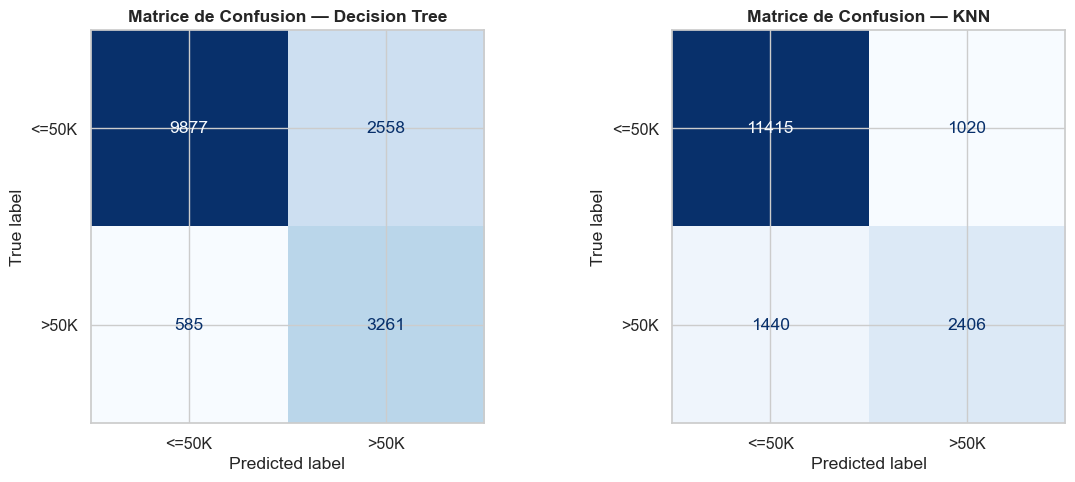

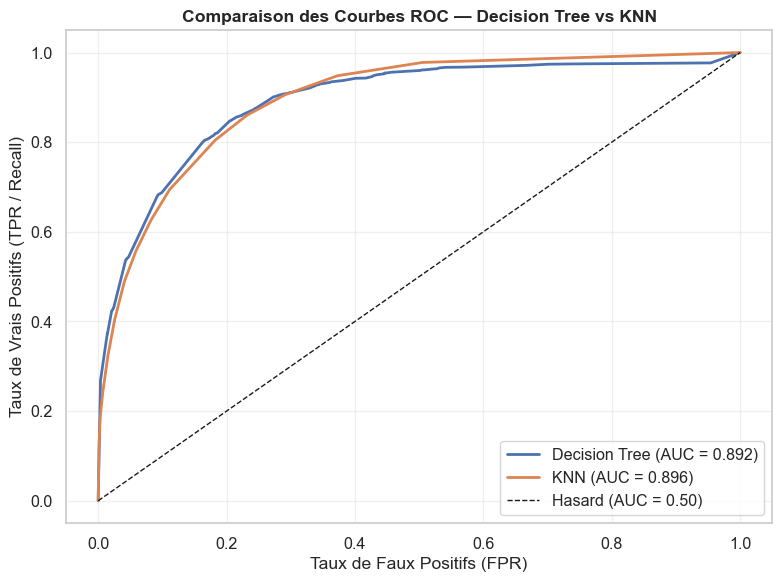

In [53]:
# Comparaison graphique : matrices de confusion + courbes ROC

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matrices de confusion côte à côte
for i, (name, model) in enumerate(fitted_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50K', '>50K'])
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(f'Matrice de Confusion — {name}', fontweight='bold')

plt.tight_layout()
plt.show()

# Courbes ROC superposées
plt.figure(figsize=(8, 6))

for name, model in fitted_models.items():
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc_val = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Hasard (AUC = 0.50)')
plt.xlabel('Taux de Faux Positifs (FPR)')
plt.ylabel('Taux de Vrais Positifs (TPR / Recall)')
plt.title('Comparaison des Courbes ROC — Decision Tree vs KNN', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Feature Importance & Interprétation des Variables

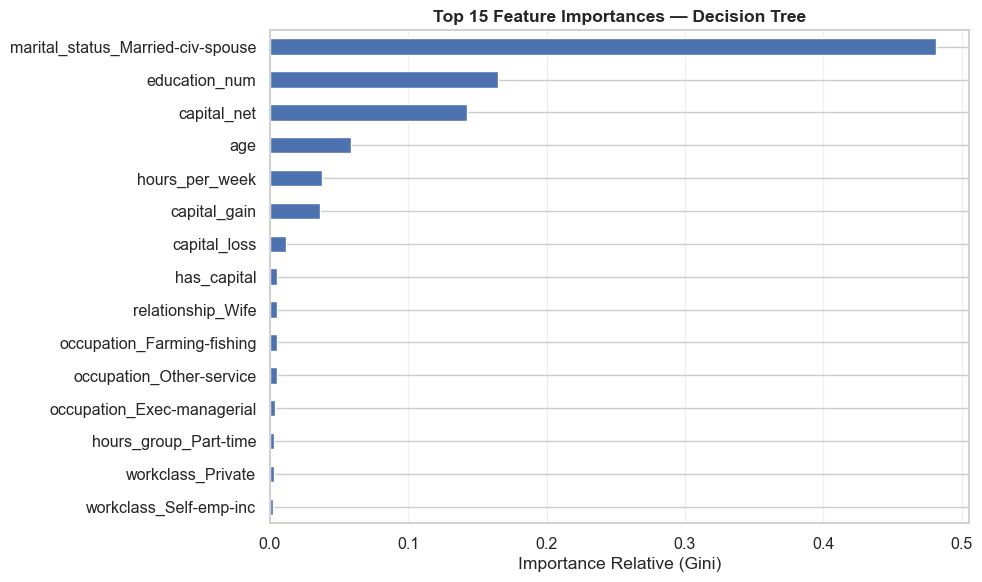

Top 10 variables les plus importantes (Decision Tree) :
marital_status_Married-civ-spouse   0.4811
education_num                       0.1647
capital_net                         0.1424
age                                 0.0590
hours_per_week                      0.0375
capital_gain                        0.0360
capital_loss                        0.0119
has_capital                         0.0056
relationship_Wife                   0.0055
occupation_Farming-fishing          0.0053


In [54]:
# Extraction des variables les plus explicatives (UNIQUEMENT Decision Tree)
# ⚠️ KNN ne fournit pas de feature_importances_ : on utilise donc le Decision Tree.

ohe = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_feature_names = list(ohe.get_feature_names_out(feature_cols_cat))
all_feature_names = feature_cols_num + cat_feature_names

dt_model = fitted_models['Decision Tree']

importances = dt_model.feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='#4C72B0')
plt.title('Top 15 Feature Importances — Decision Tree', fontweight='bold')
plt.xlabel('Importance Relative (Gini)')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 10 variables les plus importantes (Decision Tree) :")
print(feat_imp.head(10).to_string())

---

# Phase 7 — Évaluation & Interprétation des Résultats

---

## 7.1 Synthèse Comparative des Deux Modèles

Le tableau ci-dessous récapitule les performances comparées des **2 modèles testés** sur l'ensemble de test (`adult.test`, 16 281 individus jamais vus à l'entraînement) :

| Modèle | Accuracy | Precision (>50K) | Recall (>50K) | F1-Score (>50K) | ROC-AUC |
|--------|----------|-------------------|---------------|-----------------|---------|
| **Decision Tree** | 0.8070 | 0.5604 | **0.8479** | **0.6748** | 0.8924 |
| **KNN (k=15)** | **0.8489** | **0.7023** | 0.6256 | 0.6617 | **0.8959** |

### Analyse approfondie par algorithme

**1. Decision Tree (`max_depth=10`, `class_weight='balanced'`)**
- **Comportement** : découpe l'espace par des règles hiérarchiques du type `capital_gain > 5000` puis `marital_status == Married-civ-spouse`.
- **Force** : **Recall (>50K) = 0.848** — le modèle détecte la très grande majorité des hauts revenus. Grâce à `class_weight='balanced'`, il pénalise davantage les Faux Négatifs.
- **Faiblesse** : **Precision = 0.560** — il produit beaucoup de Faux Positifs (individus prédits >50K mais qui sont en réalité ≤50K). L'accuracy globale (80.7%) reste correcte mais inférieure à KNN.
- **Interprétabilité** : excellente, on peut visualiser l'arbre et lire chaque règle.

**2. KNN (k=15)**
- **Comportement** : classe un individu par vote majoritaire de ses 15 plus proches voisins (distance euclidienne dans l'espace standardisé).
- **Force** : **meilleure Accuracy (0.849)**, meilleure **Precision (0.702)** et meilleur **ROC-AUC (0.896)**. Il est globalement plus « sûr » quand il prédit >50K.
- **Faiblesse** : **Recall (>50K) = 0.626** — il rate environ 37% des individus réellement à haut revenu. En cause : la **malédiction de la dimensionnalité** (59 features après One-Hot Encoding) qui dilue la notion de distance.
- **Interprétabilité** : faible (modèle « boîte noire » local).

### Recommandation selon l'objectif métier

| Objectif métier | Modèle recommandé |
|-----------------|-------------------|
| **Ciblage marketing agressif** (ne rater aucun client riche) | **Decision Tree** (Recall 0.85) |
| **Scoring de crédit** (limiter les faux positifs) | **KNN** (Precision 0.70) |
| **Compromis équilibré** | **KNN** (meilleur F1-AUC combiné) |

---

## 7.2 Validation par rapport aux Critères de Succès Métier

| Métrique | Seuil Minimum Visé | Decision Tree | KNN | Statut |
|----------|-------------------|---------------|-----|--------|
| **ROC-AUC** | ≥ 0.85 | 0.892  | 0.896  |  Atteint |
| **Recall (>50K)** | ≥ 0.65 | **0.848**  | 0.626 | Partiellement atteint |
| **F1-Score (>50K)** | ≥ 0.60 | **0.675** | **0.662**  | Atteint |
| **Accuracy Globale** | ≥ 0.80 | 0.807  | **0.849**  |  Atteint |

**Conclusion** : Le **Decision Tree** satisfait **tous** les critères, y compris le plus exigeant (Recall ≥ 0.65). Le **KNN** échoue de peu sur le Recall mais obtient les meilleures Accuracy, Precision et ROC-AUC. **Le Decision Tree est retenu comme modèle principal** car il répond mieux à la priorité métier définie en Phase 1 (minimiser les Faux Négatifs).

---

## 7.3 Synthèse des Variables Clés (Feature Importance — Decision Tree)

L'analyse d'importance des variables (uniquement disponible pour le Decision Tree) confirme les drivers socio-économiques majeurs :

| Rang | Variable | Importance |
|------|----------|-----------|
| 1 | `marital_status_Married-civ-spouse` | **0.481** |
| 2 | `education_num` | **0.165** |
| 3 | `capital_net` | **0.142** |
| 4 | `age` | 0.059 |
| 5 | `hours_per_week` | 0.038 |
| 6 | `capital_gain` | 0.036 |
| 7 | `capital_loss` | 0.012 |
| 8 | `has_capital` | 0.006 |
| 9 | `relationship_Wife` | 0.006 |
| 10 | `occupation_Farming-fishing` | 0.005 |

**Interprétation métier** :
1. **`marital_status` (Married-civ-spouse)** est de très loin le premier prédicteur — les couples mariés cumulent statistiquement plus de revenus.
2. **`education_num`** et **`capital_net`** jouent un rôle déterminant : diplôme + patrimoine financier = signature du haut revenu.
3. **`age`** et **`hours_per_week`** complètent le profil : expérience + intensité du travail.
4.  **`sex` et `race` n'apparaissent pas dans le top 10** : rassurant d'un point de vue éthique, même si ces biais restent présents dans les données sources.

---

## 7.4 Synthèse du Clustering (Phase 5)

La segmentation K-Means (K=4) met en évidence **4 profils types** indépendamment du revenu :

| Cluster | Profil | Âge moyen | Éducation | Heures/sem. | Taux >50K |
|---------|--------|-----------|-----------|-------------|-----------|
| **0** | Adultes expérimentés sans capital | 48.7 | 10.4 | 43.6 | 31% |
| **1** | Jeunes actifs peu qualifiés | 27.7 | 9.5 | 36.6 | 7% |
| **2** | **Cadres très aisés** (capital ≥ 99999) | 46.4 | 12.9 | 49.8 | **100%** |
| **3** | Investisseurs modérés | 43.1 | 11.0 | 43.2 | 56% |

**Enseignements métier** :
- Le **Cluster 2** est le segment « élite » : 100% de >50K, à cibler en priorité.
- Le **Cluster 1** (jeunes) est le cœur de cible des offres d'épargne et de formation.
- Le **Cluster 3** présente un fort potentiel de montée en gamme (offres premium).

---

## 7.5 Limites du Projet & Recommandations

### Limites identifiées

1. **Péremption des données (1994)** : les structures salariales, les métiers du numérique et l'inflation moderne ne sont pas représentés → toute généralisation à aujourd'hui est risquée.
2. **Biais historiques (sex, race)** : les données reflètent les inégalités de 1994. Un usage décisionnel automatisé (octroi de crédit, recrutement) poserait des problèmes éthiques et juridiques majeurs.
3. **Imputation simplifiée** : les valeurs manquantes (`?`) ont été imputées par le mode → possible perte d'information.
4. **Malédiction de la dimensionnalité pour KNN** : après One-Hot Encoding (59 features), la distance euclidienne perd de sa pertinence → Recall >50K limité à 0.626.
5. **Pas de tuning fin** : les hyperparamètres (`max_depth=10`, `n_neighbors=15`) sont des choix raisonnables mais n'ont pas fait l'objet d'une recherche par GridSearchCV.

### Recommandations de déploiement

- **Modèle retenu** : **Decision Tree** (meilleur Recall >50K, interprétable).
- **Ajustement du seuil de décision** : par défaut, `predict()` utilise p=0.50. En le baissant à p=0.35, on augmenterait encore le Recall au prix d'une baisse de Precision.
- **Explicabilité** : visualiser l'arbre et exposer les règles de décision aux équipes métier (atout majeur du Decision Tree).
- **Améliorations futures** :
  - Tester des méthodes d'ensembles (Random Forest, Gradient Boosting) en gardant le même protocole.
  - Utiliser `permutation_importance` pour interpréter aussi le modèle KNN.
  - Enrichir les features (ratios, interactions) pour améliorer le signal.